# House Prices — Part C: Models

In this notebook I train and compare regression models on the data prepared in `01_EDA.ipynb`,
tune the best ones, analyse their errors and create the Kaggle submission.

## C1. Baseline and cross-validation

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", None)

processed_dir = Path("../data/processed")
results_dir = Path("../results")
figures_dir = results_dir / "figures"
submissions_dir = Path("../submissions")

train_processed = pd.read_csv(processed_dir / "train_processed.csv")
test_processed = pd.read_csv(processed_dir / "test_processed.csv")

print("Train:", train_processed.shape)
print("Test:", test_processed.shape)

Train: (1458, 262)
Test: (1459, 261)


The models predict `log(1 + SalePrice)`. Kaggle scores the submission with the RMSE between the logarithms of
the predicted and the real prices, so the RMSE on the log target is exactly the competition metric.

In [2]:
X = train_processed.drop(columns=["Id", "SalePrice"])
y = np.log1p(train_processed["SalePrice"])

X_test = test_processed.drop(columns=["Id"])
test_ids = test_processed["Id"]

print("X:", X.shape, " y:", y.shape, " X_test:", X_test.shape)

X: (1458, 260)  y: (1458,)  X_test: (1459, 260)


All models are evaluated with the **same 5 folds** (`KFold`, `shuffle=True`, `random_state=42`), so the
comparison is fair. Each fold is used once as validation data while the model is trained on the other 4 folds.

In [3]:
from sklearn.model_selection import KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(cv.split(X), start=1):
    print(f"Fold {fold}: train = {len(train_idx)}, validation = {len(val_idx)}")

Fold 1: train = 1166, validation = 292
Fold 2: train = 1166, validation = 292
Fold 3: train = 1166, validation = 292
Fold 4: train = 1167, validation = 291
Fold 5: train = 1167, validation = 291


I write one small function that I reuse for every model. In each fold the model is trained **only on the
training part** and predicts the validation part. It returns the RMSE of every fold and the
out-of-fold (OOF) predictions, which I use later for error analysis. For linear models the `StandardScaler`
is inside a pipeline, so it is also fitted only on the training part of each fold (no data leakage).

In [4]:
from sklearn.metrics import root_mean_squared_error


def evaluate(model):
    fold_rmse = []
    oof_predictions = np.zeros(len(X))

    for train_idx, val_idx in cv.split(X):
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        predictions = model.predict(X.iloc[val_idx])

        oof_predictions[val_idx] = predictions
        fold_rmse.append(root_mean_squared_error(y.iloc[val_idx], predictions))

    return np.array(fold_rmse), oof_predictions


results = []


def add_result(model_name, stage, fold_rmse, params="-"):
    results.append({
        "model": model_name,
        "stage": stage,
        "cv_rmse": fold_rmse.mean(),
        "cv_std": fold_rmse.std(),
        "params": params,
    })
    print(f"{model_name} ({stage}) RMSE per fold:", fold_rmse.round(4))
    print(f"Mean: {fold_rmse.mean():.4f} ± {fold_rmse.std():.4f}")

In [5]:
from sklearn.dummy import DummyRegressor

baseline_rmse, _ = evaluate(DummyRegressor(strategy="mean"))
add_result("Baseline", "mean price", baseline_rmse)

Baseline (mean price) RMSE per fold: [0.4106 0.3888 0.3808 0.4265 0.3897]
Mean: 0.3993 ± 0.0168


The baseline always predicts the mean log price of the training folds. Its RMSE is **0.3993**, which means
a typical error of about 40–50% of the price. Every real model must be much better than this.

## C2. Train and compare models

I train five models with default or simple settings:
- **Linear Regression** — the simplest linear model;
- **Ridge** — linear regression with an L2 penalty that shrinks the coefficients;
- **Lasso** — linear regression with an L1 penalty that can set coefficients exactly to 0 (feature selection);
- **Random Forest** — average of many deep decision trees trained on bootstrap samples;
- **Gradient Boosting** — small trees added one after another, each correcting the errors of the previous ones.

In [6]:
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

linear_rmse, _ = evaluate(make_pipeline(StandardScaler(), LinearRegression()))
add_result("Linear Regression", "initial", linear_rmse)

Linear Regression (initial) RMSE per fold: [0.1317 0.1408 0.1264 0.1467 0.1091]
Mean: 0.1309 ± 0.0130


In [7]:
ridge_rmse, _ = evaluate(make_pipeline(StandardScaler(), Ridge(alpha=1.0)))
add_result("Ridge", "initial", ridge_rmse, "alpha=1")

Ridge (initial) RMSE per fold: [0.1303 0.14   0.1261 0.1465 0.1089]
Mean: 0.1304 ± 0.0129


In [8]:
lasso_rmse, _ = evaluate(make_pipeline(StandardScaler(), Lasso(alpha=0.001, max_iter=50000)))
add_result("Lasso", "initial", lasso_rmse, "alpha=0.001")

Lasso (initial) RMSE per fold: [0.1199 0.1258 0.1194 0.1298 0.1036]
Mean: 0.1197 ± 0.0089


In [9]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

forest_rmse, _ = evaluate(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1))
add_result("Random Forest", "initial", forest_rmse, "n_estimators=300")

Random Forest (initial) RMSE per fold: [0.1434 0.1275 0.1397 0.1361 0.1293]
Mean: 0.1352 ± 0.0060


In [10]:
boosting_rmse, _ = evaluate(GradientBoostingRegressor(random_state=42))
add_result("Gradient Boosting", "initial", boosting_rmse, "n_estimators=100, learning_rate=0.1, max_depth=3")

Gradient Boosting (initial) RMSE per fold: [0.1231 0.1179 0.1244 0.1341 0.1165]
Mean: 0.1232 ± 0.0062


In [11]:
pd.DataFrame(results).sort_values("cv_rmse").round(4)

,model,stage,cv_rmse,cv_std,params
3,Lasso,initial,0.1197,0.0089,alpha=0.001
5,Gradient Boosting,initial,0.1232,0.0062,"n_estimators=100, learning_rate=0.1, max_depth=3"
2,Ridge,initial,0.1304,0.0129,alpha=1
1,Linear Regression,initial,0.1309,0.0130,-
4,Random Forest,initial,0.1352,0.0060,n_estimators=300
0,Baseline,mean price,0.3993,0.0168,-


- All models are about 3 times better than the baseline.
- **Lasso** is the best initial model (0.1197). With 260 columns, many of them rare dummy columns, the L1 penalty
  removes useless features and reduces overfitting.
- Linear Regression and Ridge with a small `alpha=1` are almost identical (≈ 0.130), and they have the largest
  differences between folds (std ≈ 0.013): they overfit some folds.
- Random Forest is the weakest model here (0.1352). Gradient Boosting (0.1232) is better because each new tree
  corrects the errors of the previous trees.

## C3. Hyperparameter tuning

I tune Ridge, Lasso and Gradient Boosting with `GridSearchCV`, using the same 5 folds.
`GridSearchCV` trains the model for every combination of parameters and keeps the one with the lowest mean
RMSE. The scaler is inside the pipeline, so it is refitted in every fold of the search.

Note: the best parameters are chosen and scored on the same folds, so the tuned scores are slightly optimistic.

In [12]:
from sklearn.model_selection import GridSearchCV


def tune(model_name, model, param_grid):
    search = GridSearchCV(model, param_grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)

    best = search.best_index_
    fold_rmse = np.array([-search.cv_results_[f"split{k}_test_score"][best] for k in range(5)])
    params = ", ".join(f"{key.split('__')[-1]}={value}" for key, value in search.best_params_.items())

    print("Best parameters:", params)
    add_result(model_name, "tuned", fold_rmse, params)
    return search

In [13]:
ridge_search = tune(
    "Ridge",
    make_pipeline(StandardScaler(), Ridge()),
    {"ridge__alpha": [1, 10, 30, 100, 200, 300, 500, 1000, 2000]},
)

Best parameters: alpha=500
Ridge (tuned) RMSE per fold: [0.1286 0.1203 0.1159 0.1249 0.104 ]
Mean: 0.1187 ± 0.0085


In [14]:
lasso_search = tune(
    "Lasso",
    make_pipeline(StandardScaler(), Lasso(max_iter=50000)),
    {"lasso__alpha": [0.0001, 0.0005, 0.001, 0.002, 0.003, 0.005, 0.01, 0.02]},
)

Best parameters: alpha=0.005
Lasso (tuned) RMSE per fold: [0.1147 0.112  0.122  0.1142 0.1012]
Mean: 0.1128 ± 0.0067


In [15]:
boosting_search = tune(
    "Gradient Boosting",
    GradientBoostingRegressor(subsample=0.8, random_state=42),
    {
        "n_estimators": [300, 1000],
        "learning_rate": [0.03, 0.1],
        "max_depth": [2, 3, 4],
    },
)

Best parameters: learning_rate=0.03, max_depth=3, n_estimators=1000
Gradient Boosting (tuned) RMSE per fold: [0.1105 0.1123 0.1193 0.1254 0.1138]
Mean: 0.1162 ± 0.0054


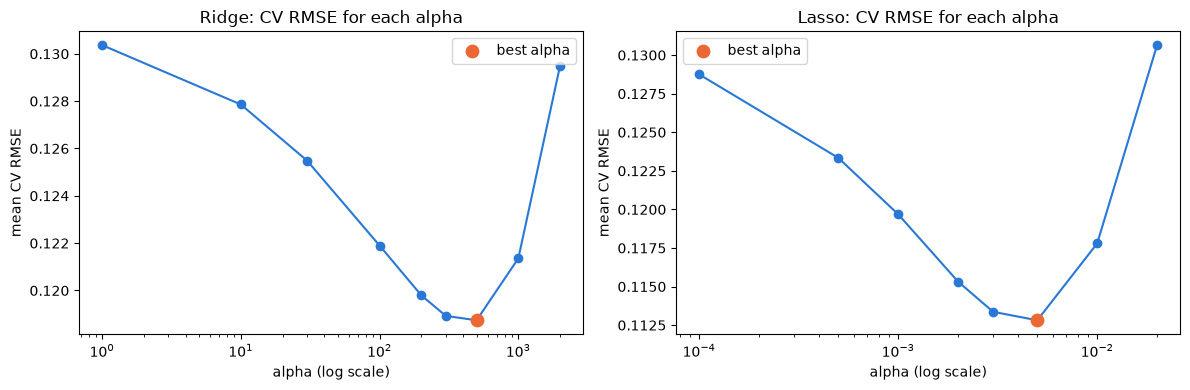

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, search, name in [(axes[0], ridge_search, "ridge"), (axes[1], lasso_search, "lasso")]:
    alphas = search.cv_results_[f"param_{name}__alpha"].data.astype(float)
    rmse = -search.cv_results_["mean_test_score"]
    ax.plot(alphas, rmse, marker="o", color="#2a78d6")
    ax.scatter(search.best_params_[f"{name}__alpha"], -search.best_score_, s=80, color="#eb6834", zorder=3,
               label="best alpha")
    ax.set_xscale("log")
    ax.set_title(f"{name.capitalize()}: CV RMSE for each alpha")
    ax.set_xlabel("alpha (log scale)")
    ax.set_ylabel("mean CV RMSE")
    ax.legend()

plt.tight_layout()
fig.savefig(figures_dir / "07_regularization_tuning.png", dpi=120)
plt.show()

- **Ridge:** a much stronger penalty than the default is best (`alpha=500`): 0.1304 → 0.1187.
- **Lasso:** best `alpha=0.005`: 0.1197 → **0.1128**.
- **Gradient Boosting:** more trees with a smaller learning rate (`n_estimators=1000`, `learning_rate=0.03`,
  `max_depth=3`): 0.1232 → 0.1162.

The curves show the usual U shape: a small `alpha` overfits (the model follows noise), a large `alpha` underfits
(the coefficients are shrunk too much). The best values are inside the grid, not at its edge.

## C4. Model comparison

In [17]:
comparison = pd.DataFrame(results).sort_values("cv_rmse").reset_index(drop=True)
comparison.index = comparison.index + 1

comparison.round(4).to_csv(results_dir / "model_comparison.csv", index_label="rank")
comparison.round(4)

,model,stage,cv_rmse,cv_std,params
1,Lasso,tuned,0.1128,0.0067,alpha=0.005
2,Gradient Boosting,tuned,0.1162,0.0054,"learning_rate=0.03, max_depth=3, n_estimators=1000"
3,Ridge,tuned,0.1187,0.0085,alpha=500
4,Lasso,initial,0.1197,0.0089,alpha=0.001
5,Gradient Boosting,initial,0.1232,0.0062,"n_estimators=100, learning_rate=0.1, max_depth=3"
6,Ridge,initial,0.1304,0.0129,alpha=1
7,Linear Regression,initial,0.1309,0.0130,-
8,Random Forest,initial,0.1352,0.0060,n_estimators=300
9,Baseline,mean price,0.3993,0.0168,-


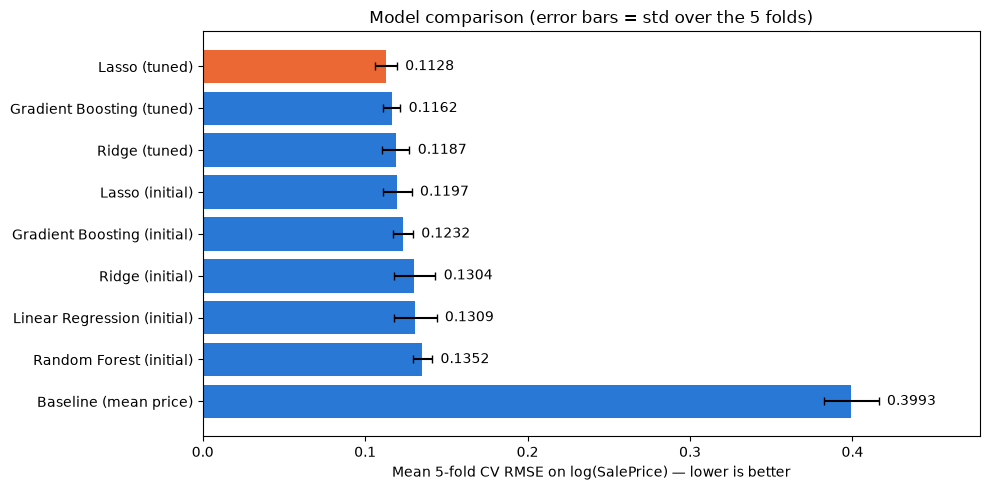

In [18]:
labels = comparison["model"] + " (" + comparison["stage"] + ")"
colors = ["#eb6834"] + ["#2a78d6"] * (len(comparison) - 1)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(labels, comparison["cv_rmse"], xerr=comparison["cv_std"], color=colors, capsize=3)
ax.bar_label(bars, fmt="%.4f", padding=6)
ax.invert_yaxis()
ax.set_xlabel("Mean 5-fold CV RMSE on log(SalePrice) — lower is better")
ax.set_title("Model comparison (error bars = std over the 5 folds)")
ax.margins(x=0.15)

plt.tight_layout()
fig.savefig(figures_dir / "08_model_comparison.png", dpi=120)
plt.show()

In [19]:
winner = comparison.iloc[0]
print("Best model:", winner["model"], f"({winner['stage']})")
print("Parameters:", winner["params"])
print(f"CV RMSE: {winner['cv_rmse']:.4f} ± {winner['cv_std']:.4f}")

Best model: Lasso (tuned)
Parameters: alpha=0.005
CV RMSE: 0.1128 ± 0.0067


In [20]:
tuned_models = {
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_,
    "Gradient Boosting": boosting_search.best_estimator_,
}
best_model = tuned_models[winner["model"]]

lasso_coefficients = lasso_search.best_estimator_[-1].coef_
print("Lasso keeps", (lasso_coefficients != 0).sum(), "of", len(lasso_coefficients), "features")

Lasso keeps 76 of 260 features


**The best model is the tuned Lasso (`alpha=0.005`) with a CV RMSE of 0.1128 ± 0.0067.**

- It is better than tuned Gradient Boosting (0.1162) in 3 of the 5 folds; the difference is small compared with
  the variation between folds.
- On the log scale, the price is close to a linear function of quality, size, age and neighborhood, so a linear
  model works very well.
- Lasso keeps only 76 of the 260 features and sets the others to 0. This is a simpler model that generalizes better.

## C5. Error analysis

For the error analysis I use the **out-of-fold predictions** of the best model: every training house is
predicted by a model that did not see it during training.

In [21]:
from sklearn.base import clone
from sklearn.metrics import r2_score

best_fold_rmse, oof_predictions = evaluate(clone(best_model))

print(f"OOF RMSE: {root_mean_squared_error(y, oof_predictions):.4f}")
print(f"OOF R²: {r2_score(y, oof_predictions):.4f}")

OOF RMSE: 0.1130
OOF R²: 0.9200


In [22]:
raw_train = pd.read_csv("../data/raw/train.csv")

errors = pd.DataFrame({
    "Id": train_processed["Id"],
    "actual_price": train_processed["SalePrice"],
    "predicted_price": np.expm1(oof_predictions).round(0),
    "log_error": oof_predictions - y,
})
errors["abs_log_error"] = errors["log_error"].abs()
errors["percent_error"] = (100 * (errors["predicted_price"] / errors["actual_price"] - 1)).round(1)
errors = errors.merge(raw_train[["Id", "OverallQual", "GrLivArea", "Neighborhood", "SaleCondition"]], on="Id")

print(f"Median absolute error: ${(errors['predicted_price'] - errors['actual_price']).abs().median():,.0f}")
print(f"Median percent error: {errors['percent_error'].abs().median():.1f}%")

largest_errors = errors.sort_values("abs_log_error", ascending=False).head(10)
largest_errors.set_index("Id").round(3)

Median absolute error: $9,652
Median percent error: 5.9%


,actual_price,predicted_price,log_error,abs_log_error,percent_error,OverallQual,GrLivArea,Neighborhood,SaleCondition
Id,,,,,,,,,
633,82500,183532.0,0.800,0.800,122.5,7,1411,NWAmes,Family
31,40000,77569.0,0.662,0.662,93.9,4,1317,IDOTRR,Normal
1325,147000,281009.0,0.648,0.648,91.2,8,1795,Somerst,Partial
463,62383,118679.0,0.643,0.643,90.2,5,864,Sawyer,Normal
969,37900,71080.0,0.629,0.629,87.5,3,968,OldTown,Abnorml
411,60000,108449.0,0.592,0.592,80.7,5,1276,Edwards,Abnorml
89,85000,49618.0,-0.538,0.538,-41.6,3,1526,IDOTRR,Abnorml
496,34900,58717.0,0.520,0.520,68.2,4,720,IDOTRR,Abnorml
1001,82000,50204.0,-0.491,0.491,-38.8,3,944,Edwards,Normal


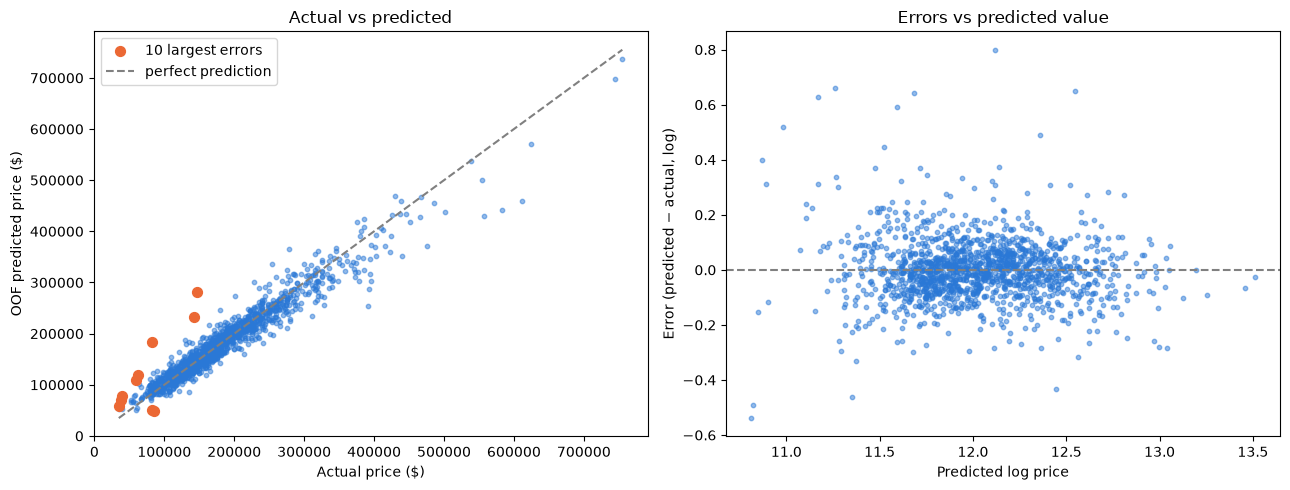

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(errors["actual_price"], errors["predicted_price"], s=10, alpha=0.5, color="#2a78d6")
axes[0].scatter(largest_errors["actual_price"], largest_errors["predicted_price"], s=50, color="#eb6834",
                label="10 largest errors")
limits = [errors["actual_price"].min(), errors["actual_price"].max()]
axes[0].plot(limits, limits, color="gray", linestyle="--", label="perfect prediction")
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("OOF predicted price ($)")
axes[0].set_title("Actual vs predicted")
axes[0].legend()

axes[1].scatter(oof_predictions, errors["log_error"], s=10, alpha=0.5, color="#2a78d6")
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set_xlabel("Predicted log price")
axes[1].set_ylabel("Error (predicted − actual, log)")
axes[1].set_title("Errors vs predicted value")

plt.tight_layout()
fig.savefig(figures_dir / "09_error_analysis.png", dpi=120)
plt.show()

In [24]:
def group_rmse(column):
    return (errors.groupby(column)
            .apply(lambda g: pd.Series({"houses": len(g), "rmse": np.sqrt((g["log_error"] ** 2).mean())}),
                   include_groups=False)
            .astype({"houses": int})
            .sort_values("rmse", ascending=False))

group_rmse("SaleCondition").round(4)

,houses,rmse
SaleCondition,,
Family,20,0.2286
Abnorml,101,0.1908
Alloca,12,0.1893
Partial,123,0.1369
AdjLand,4,0.0996
Normal,1198,0.0964


In [25]:
group_rmse("Neighborhood").head(5).round(4)

,houses,rmse
Neighborhood,,
IDOTRR,37,0.2235
ClearCr,28,0.1598
Edwards,98,0.1431
OldTown,113,0.1414
BrkSide,58,0.1346


**Observations**
- The typical error is small: the median error is about 6% of the price (≈ \$9,650), and R² on the log scale is 0.92.
- The largest errors are mostly **non-normal sales**. 7 of the 10 largest errors are `Family`, `Abnorml`
  (e.g. foreclosure) or `Partial` sales. For `Family` and `Abnorml` sales the RMSE is about 2 times
  higher than for `Normal` sales (0.23 and 0.19 vs 0.10). The price of these sales does not depend only on the house,
  and the model has no information about the circumstances of the sale.
- 8 of the 10 largest errors are **overestimates of cheap, old houses** (for example Id 633: actual \$82,500, predicted
  \$183,532). `IDOTRR`, a cheap neighborhood, has the highest error (0.22).
- The right plot shows that the errors are centred around 0 for all price levels, but the biggest errors are at low
  prices: the model pulls extreme prices towards the average.

## C6. Kaggle submission

The best model is trained again on **all** training houses (the test set is never used for training),
then it predicts the test houses. Predictions are converted back to dollars with `np.expm1`.

In [26]:
final_model = clone(best_model)
final_model.fit(X, y)

test_predictions = np.expm1(final_model.predict(X_test))

print("Number of predictions:", len(test_predictions))
print(f"Min: ${test_predictions.min():,.0f}  Median: ${np.median(test_predictions):,.0f}  Max: ${test_predictions.max():,.0f}")
print(f"Training prices: ${train_processed['SalePrice'].min():,.0f} – ${train_processed['SalePrice'].max():,.0f}")

Number of predictions: 1459
Min: $42,690  Median: $157,327  Max: $1,641,616
Training prices: $34,900 – $755,000


One test house (Id 2550) gets a prediction of about \$1.6 million, more than twice the most expensive training house.
It has 5,095 sq ft and quality 10, like the two outliers removed in B5, and the linear model extrapolates far
outside the data it has seen. To avoid an extreme prediction, I clip all predictions to the range of the training
prices (\$34,900 – \$755,000). This changes only this one house.

In [27]:
low, high = train_processed["SalePrice"].min(), train_processed["SalePrice"].max()
outside = (test_predictions < low) | (test_predictions > high)
print("Predictions outside the training range:", outside.sum(), "-> Id", test_ids[outside].tolist())
test_predictions = np.clip(test_predictions, low, high)

Predictions outside the training range: 1 -> Id [2550]


In [28]:
submission = pd.DataFrame({"Id": test_ids, "SalePrice": test_predictions})
sample = pd.read_csv("../data/raw/sample_submission.csv")

assert list(submission.columns) == list(sample.columns)
assert submission.shape == sample.shape == (1459, 2)
assert (submission["Id"].values == sample["Id"].values).all()
assert submission["SalePrice"].notna().all() and (submission["SalePrice"] > 0).all()

model_name = winner["model"].lower().replace(" ", "_")
submission_path = submissions_dir / f"submission_{model_name}.csv"
submission.to_csv(submission_path, index=False)

print("All checks passed. Saved:", submission_path)
submission.head()

All checks passed. Saved: ../submissions/submission_lasso.csv


,Id,SalePrice
0,1461,120045.355905
1,1462,155898.452921
2,1463,175905.287864
3,1464,196152.106503
4,1465,196298.845650


### Kaggle score

**Public score: _pending_** — filled in after uploading the submission file to Kaggle.

![Kaggle score](../submissions/kaggle_score.png)

## Conclusion

- The best model is **Lasso with `alpha=0.005`**, with a 5-fold CV RMSE of **0.1128** on the log price
  (baseline 0.3993).
- Tuning improved every tuned model; regularization was the most important factor for the linear models.
- The largest errors are non-normal sales and cheap old houses, which the features cannot fully explain.
- Possible improvements: averaging Lasso and Gradient Boosting predictions, log-transforming skewed area features,
  and trying XGBoost or LightGBM.